In [4]:
import os

print(os.listdir('/content'))

['.config', 'Salary_dataset.csv', '.ipynb_checkpoints', 'sample_data']


In [7]:
import os

for file in os.listdir('/content'):
    print(file)

.config
Salary_dataset.csv
.ipynb_checkpoints
sample_data


In [10]:
import pandas as pd

df = pd.read_csv('/content/Salary_dataset.csv')

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [11]:
df.shape

(30, 3)

In [12]:
df.columns

Index(['Unnamed: 0', 'YearsExperience', 'Salary'], dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [15]:
df.tail()

,Unnamed: 0,YearsExperience,Salary
25,25,9.1,105583.0
26,26,9.6,116970.0
27,27,9.7,112636.0
28,28,10.4,122392.0
29,29,10.6,121873.0


In [17]:
df.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


In [18]:
df.isnull().sum()

,0
Unnamed: 0,0
YearsExperience,0
Salary,0


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.nunique()

,0
Unnamed: 0,30
YearsExperience,28
Salary,30


In [21]:
df = df.drop(columns=['Unnamed: 0'])

df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [24]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


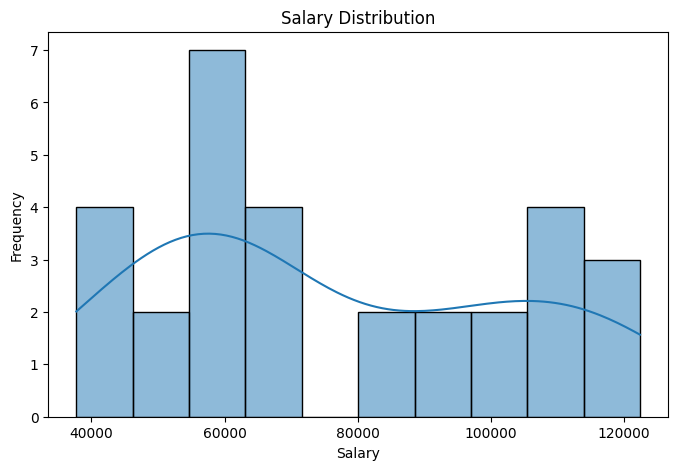

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(df['Salary'], bins=10, kde=True)

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

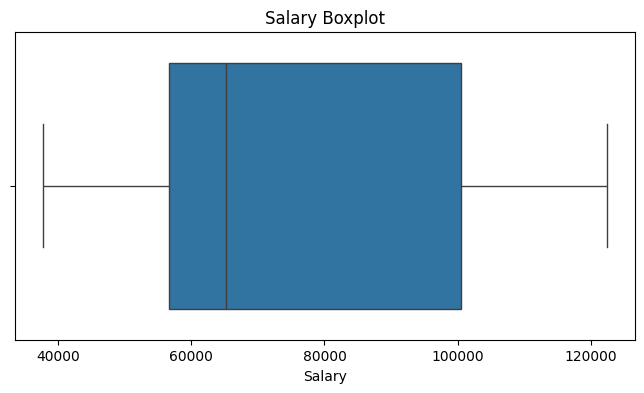

In [26]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Salary'])

plt.title('Salary Boxplot')

plt.show()

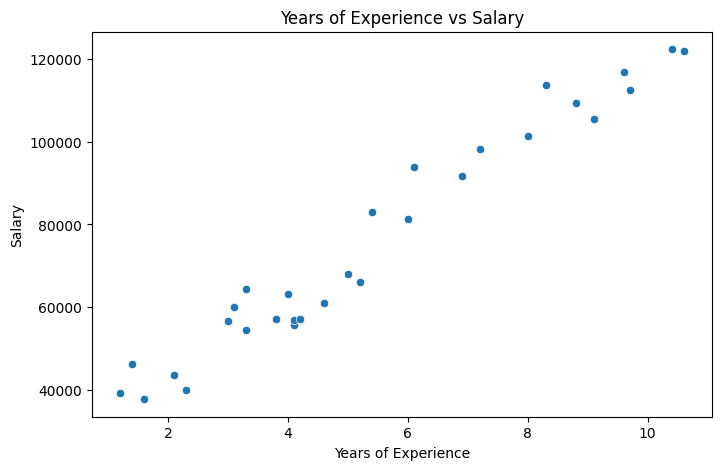

In [27]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='YearsExperience',
    y='Salary',
    data=df
)

plt.title('Years of Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.show()

In [28]:
correlation = df.corr()

print(correlation)

                 YearsExperience    Salary
YearsExperience         1.000000  0.978242
Salary                  0.978242  1.000000


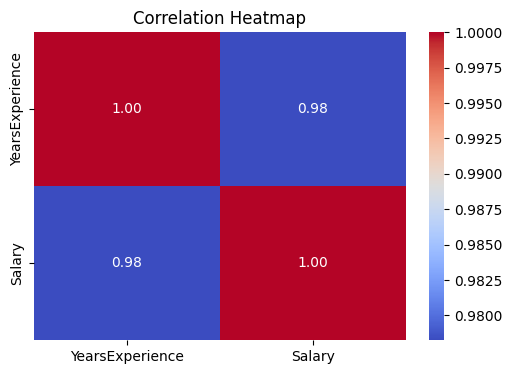

In [29]:
plt.figure(figsize=(6,4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [30]:
X = df[['YearsExperience']]

X.head()

,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3


In [31]:
y = df['Salary']

y.head()

,Salary
0,39344.0
1,46206.0
2,37732.0
3,43526.0
4,39892.0


In [32]:
print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [34]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (24, 1)
X_test: (6, 1)
y_train: (24,)
y_test: (6,)


In [35]:
print(X.shape)
print(y.shape)
print(X_train.shape)
print(X_test.shape)

(30, 1)
(30,)
(24, 1)
(6, 1)


In [36]:
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully!")

Linear Regression imported successfully!


In [37]:
model = LinearRegression()

print("Model created successfully!")

Model created successfully!


In [38]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [39]:
print("Intercept:", model.intercept_)

print("Coefficient:", model.coef_[0])

Intercept: 24380.201479473704
Coefficient: 9423.815323030976


In [40]:
y_pred = model.predict(X_test)

print("Predicted Salaries:")
print(y_pred)

Predicted Salaries:
[115791.21011287  71499.27809463 102597.86866063  75268.80422384
  55478.79204548  60190.69970699]


In [41]:
comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

comparison.head(10)

,Actual Salary,Predicted Salary
0,112636.0,115791.210113
1,67939.0,71499.278095
2,113813.0,102597.868661
3,83089.0,75268.804224
4,64446.0,55478.792045
5,57190.0,60190.699707


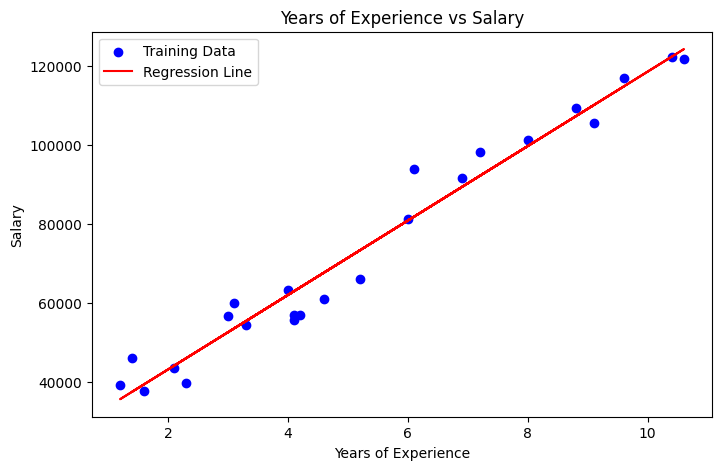

In [42]:
plt.figure(figsize=(8,5))

plt.scatter(
    X_train,
    y_train,
    color='blue',
    label='Training Data'
)

plt.plot(
    X_train,
    model.predict(X_train),
    color='red',
    label='Regression Line'
)

plt.title('Years of Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()

plt.show()

In [43]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [44]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 7059.04362190151


In [45]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.9024461774180497


In [46]:
print("Single Linear Regression Results")
print("---------------------------------")
print("RMSE:", rmse)
print("R2 Score:", r2)

Single Linear Regression Results
---------------------------------
RMSE: 7059.04362190151
R2 Score: 0.9024461774180497


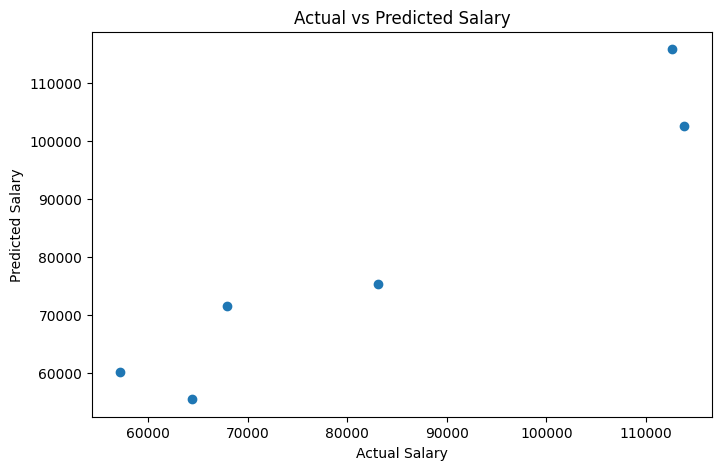

In [47]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

In [48]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 6286.453830757745


In [49]:
comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

comparison['Error'] = (
    comparison['Actual Salary'] -
    comparison['Predicted Salary']
)

comparison['Absolute Error'] = comparison['Error'].abs()

comparison.head(10)

,Actual Salary,Predicted Salary,Error,Absolute Error
0,112636.0,115791.210113,-3155.210113,3155.210113
1,67939.0,71499.278095,-3560.278095,3560.278095
2,113813.0,102597.868661,11215.131339,11215.131339
3,83089.0,75268.804224,7820.195776,7820.195776
4,64446.0,55478.792045,8967.207955,8967.207955
5,57190.0,60190.699707,-3000.699707,3000.699707


In [50]:
import pandas as pd

url = "https://raw.githubusercontent.com/AnnaMoy/portfolio/refs/heads/main/Employer's%20Salary%20Job%20Title%20and%20Country%20Information/Salary_Data.csv"

df_multi = pd.read_csv(url)

print("Dataset downloaded successfully!")

df_multi.head()

Dataset downloaded successfully!


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [51]:
print("Dataset Shape:", df_multi.shape)

print("Columns:", df_multi.columns.tolist())

Dataset Shape: (6704, 6)
Columns: ['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


In [52]:
df_multi.to_csv("Salary_Multiple_Regression.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [53]:
from google.colab import files

files.download("Salary_Multiple_Regression.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
df_multi.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [55]:
df_multi.shape

(6704, 6)

In [56]:
df_multi.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [57]:
df_multi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [58]:
df_multi.isnull().sum()

,0
Age,2
Gender,2
Education Level,3
Job Title,2
Years of Experience,3
Salary,5


In [59]:
df_multi.duplicated().sum()

np.int64(4912)

In [60]:
df_multi.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [61]:
df_clean = df_multi.copy()

In [62]:
df_clean = df_clean.drop_duplicates()

print("Duplicates removed!")

Duplicates removed!


In [63]:
df_clean.isnull().sum()

,0
Age,1
Gender,1
Education Level,2
Job Title,1
Years of Experience,2
Salary,4


In [64]:
text_columns = df_clean.select_dtypes(include='object').columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

In [65]:
df_clean = df_clean.dropna(subset=['Salary'])

In [66]:
print("Cleaned dataset shape:", df_clean.shape)

print(df_clean.isnull().sum())

Cleaned dataset shape: (1788, 6)
Age                    0
Gender                 0
Education Level        1
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


In [67]:
df_clean.to_csv('Salary_Multiple_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported!")

Visualization libraries imported!


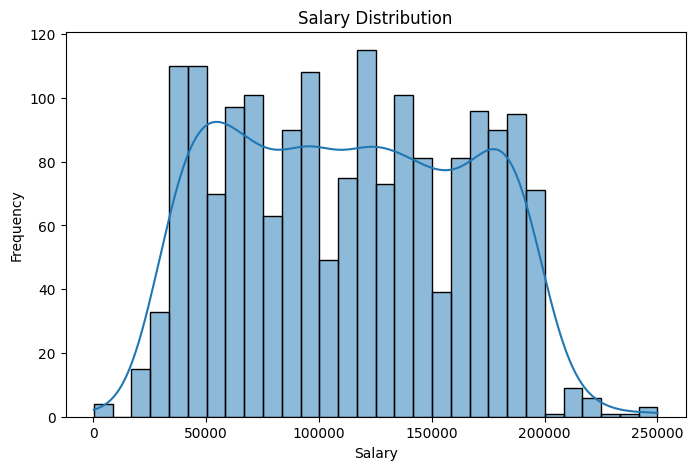

In [69]:
plt.figure(figsize=(8,5))

sns.histplot(data=df_clean, x='Salary', bins=30, kde=True)

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

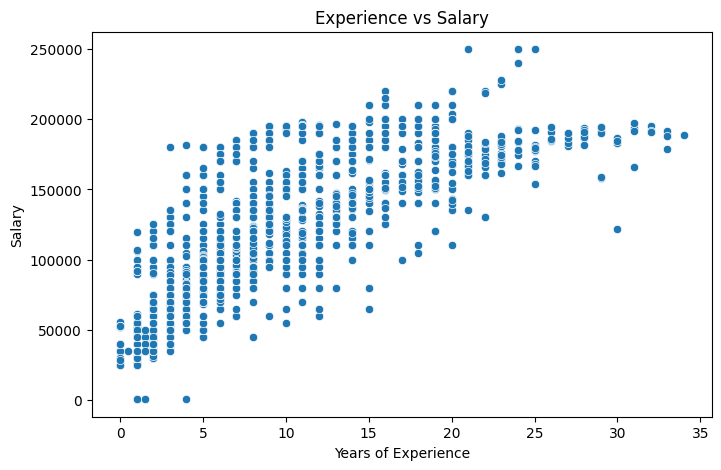

In [70]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_clean,
    x='Years of Experience',
    y='Salary'
)

plt.title('Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.show()

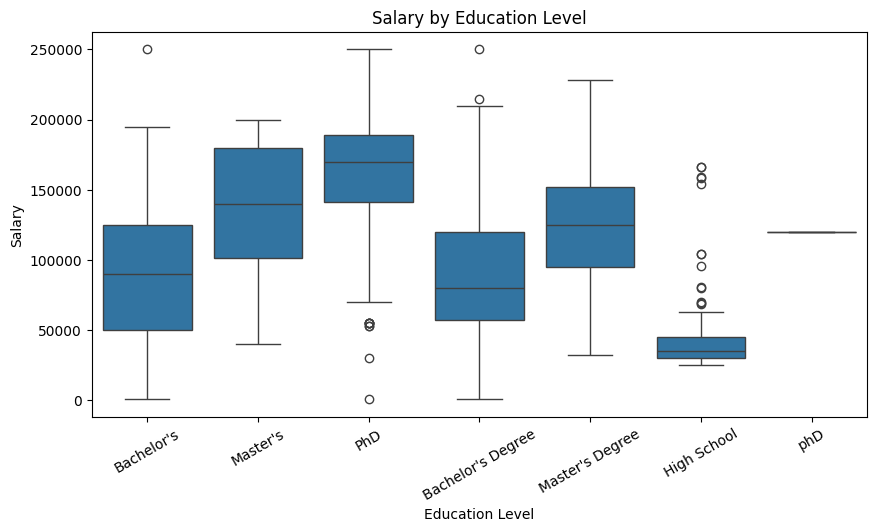

In [71]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df_clean,
    x='Education Level',
    y='Salary'
)

plt.title('Salary by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Salary')

plt.xticks(rotation=30)
plt.show()

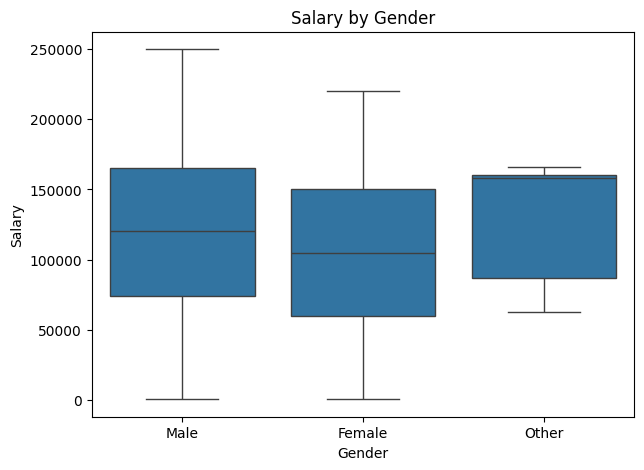

In [72]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_clean,
    x='Gender',
    y='Salary'
)

plt.title('Salary by Gender')
plt.xlabel('Gender')
plt.ylabel('Salary')

plt.show()

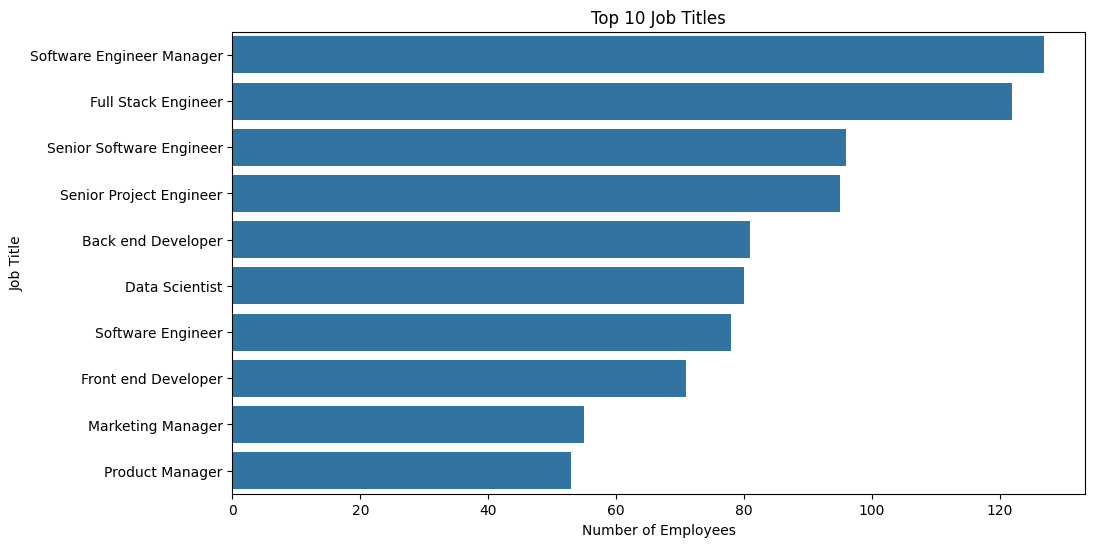

In [73]:
top_jobs = df_clean['Job Title'].value_counts().head(10)

plt.figure(figsize=(11,6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title('Top 10 Job Titles')
plt.xlabel('Number of Employees')
plt.ylabel('Job Title')

plt.show()

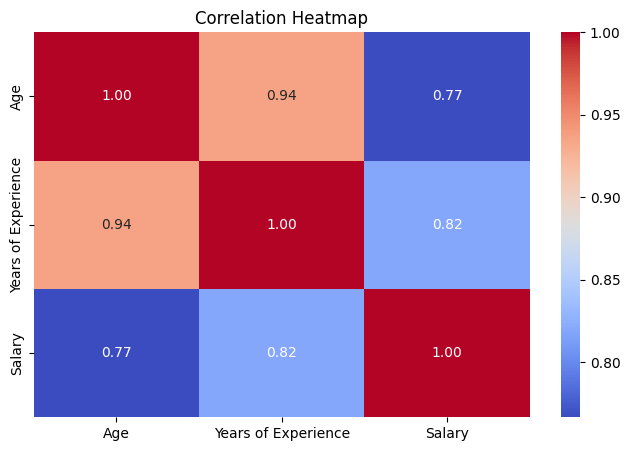

In [74]:
numeric_df = df_clean.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(8,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [75]:
X = df_clean.drop(columns=['Salary'])

X.head()

,Age,Gender,Education Level,Job Title,Years of Experience
0,32.0,Male,Bachelor's,Software Engineer,5.0
1,28.0,Female,Master's,Data Analyst,3.0
2,45.0,Male,PhD,Senior Manager,15.0
3,36.0,Female,Bachelor's,Sales Associate,7.0
4,52.0,Male,Master's,Director,20.0


In [76]:
y = df_clean['Salary']

y.head()

,Salary
0,90000.0
1,65000.0
2,150000.0
3,60000.0
4,200000.0


In [77]:
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (1788, 5)
Target variable shape: (1788,)


In [78]:
numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['Age', 'Years of Experience']
Categorical columns: ['Gender', 'Education Level', 'Job Title']


In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1430, 5)
Testing data: (358, 5)


In [80]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [81]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

In [82]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [83]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

In [84]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (1430, 187)
Processed testing shape: (358, 187)


In [85]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Processed X_train:", X_train_processed.shape)
print("Processed X_test:", X_test_processed.shape)

X_train: (1430, 5)
X_test: (358, 5)
Processed X_train: (1430, 187)
Processed X_test: (358, 187)


In [86]:
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully!")

Linear Regression imported successfully!


In [87]:
multi_model = LinearRegression()

print("Multiple Linear Regression model created!")

Multiple Linear Regression model created!


In [88]:
multi_model.fit(X_train_processed, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [89]:
y_pred_multi = multi_model.predict(X_test_processed)

print("Predicted Salaries:")
print(y_pred_multi[:10])

Predicted Salaries:
[ 55202.1900473  124617.08325239 167871.16618857  47260.17350056
  21660.56147066 116360.89786569  97717.20496984 135444.94269131
 118355.78046948 133971.66002664]


In [90]:
comparison_multi = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred_multi
})

comparison_multi.head(10)

,Actual Salary,Predicted Salary
0,65000.0,55202.190047
1,100000.0,124617.083252
2,180000.0,167871.166189
3,50000.0,47260.173501
4,25000.0,21660.561471
5,140000.0,116360.897866
6,100000.0,97717.204970
7,100000.0,135444.942691
8,145000.0,118355.780469
9,135000.0,133971.660027


In [92]:
print("Intercept:", multi_model.intercept_)

print("Number of coefficients:", len(multi_model.coef_))

Intercept: 2736.9868281691597
Number of coefficients: 187


In [93]:
print("Intercept:", multi_model.intercept_)
print("Number of coefficients:", len(multi_model.coef_))
print(comparison_multi.head(10))

Intercept: 2736.9868281691597
Number of coefficients: 187
   Actual Salary  Predicted Salary
0        65000.0      55202.190047
1       100000.0     124617.083252
2       180000.0     167871.166189
3        50000.0      47260.173501
4        25000.0      21660.561471
5       140000.0     116360.897866
6       100000.0      97717.204970
7       100000.0     135444.942691
8       145000.0     118355.780469
9       135000.0     133971.660027


In [94]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np

In [95]:
rmse_multi = np.sqrt(
    mean_squared_error(y_test, y_pred_multi)
)

print("Multiple Regression RMSE:", rmse_multi)

Multiple Regression RMSE: 19969.96193269291


In [96]:
mae_multi = mean_absolute_error(
    y_test,
    y_pred_multi
)

print("Multiple Regression MAE:", mae_multi)

Multiple Regression MAE: 14825.016782506691


In [97]:
r2_multi = r2_score(
    y_test,
    y_pred_multi
)

print("Multiple Regression R2 Score:", r2_multi)

Multiple Regression R2 Score: 0.8541615713792057


In [98]:
print("MULTIPLE LINEAR REGRESSION RESULTS")
print("-----------------------------------")

print("RMSE:", rmse_multi)
print("MAE:", mae_multi)
print("R2 Score:", r2_multi)

MULTIPLE LINEAR REGRESSION RESULTS
-----------------------------------
RMSE: 19969.96193269291
MAE: 14825.016782506691
R2 Score: 0.8541615713792057


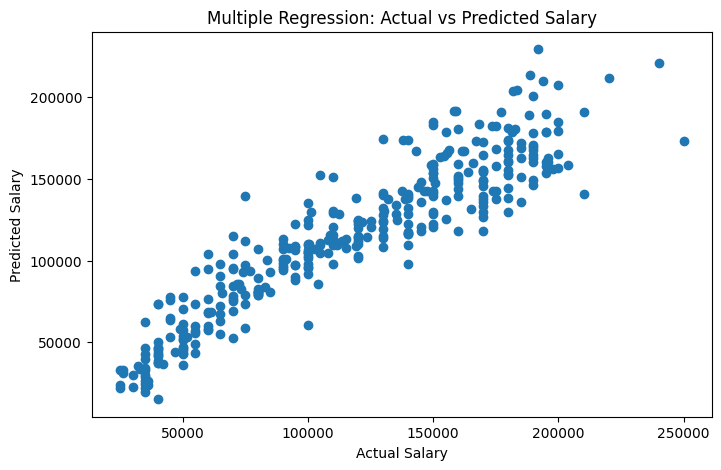

In [99]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred_multi)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")

plt.title("Multiple Regression: Actual vs Predicted Salary")

plt.show()

In [100]:
print("RMSE:", rmse_multi)
print("MAE:", mae_multi)
print("R2 Score:", r2_multi)

RMSE: 19969.96193269291
MAE: 14825.016782506691
R2 Score: 0.8541615713792057


In [101]:
X_single = df_clean[['Years of Experience']]
y_single = df_clean['Salary']

In [102]:
X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_single,
    y_single,
    test_size=0.2,
    random_state=42
)

In [103]:
single_model = LinearRegression()

single_model.fit(X_train_single, y_train_single)

print("Single Linear Regression trained successfully!")

Single Linear Regression trained successfully!


In [104]:
y_pred_single = single_model.predict(X_test_single)

In [105]:
rmse_single = np.sqrt(
    mean_squared_error(y_test_single, y_pred_single)
)

mae_single = mean_absolute_error(
    y_test_single, y_pred_single
)

r2_single = r2_score(
    y_test_single, y_pred_single
)

print("Single Regression Results")
print("--------------------------")
print("RMSE:", rmse_single)
print("MAE:", mae_single)
print("R2 Score:", r2_single)

Single Regression Results
--------------------------
RMSE: 31488.553011520096
MAE: 24571.84972344599
R2 Score: 0.6374040822855992


In [106]:
model_comparison = pd.DataFrame({
    'Model': [
        'Single Linear Regression',
        'Multiple Linear Regression'
    ],
    'RMSE': [
        rmse_single,
        rmse_multi
    ],
    'MAE': [
        mae_single,
        mae_multi
    ],
    'R2 Score': [
        r2_single,
        r2_multi
    ]
})

model_comparison

,Model,RMSE,MAE,R2 Score
0,Single Linear Regression,31488.553012,24571.849723,0.637404
1,Multiple Linear Regression,19969.961933,14825.016783,0.854162


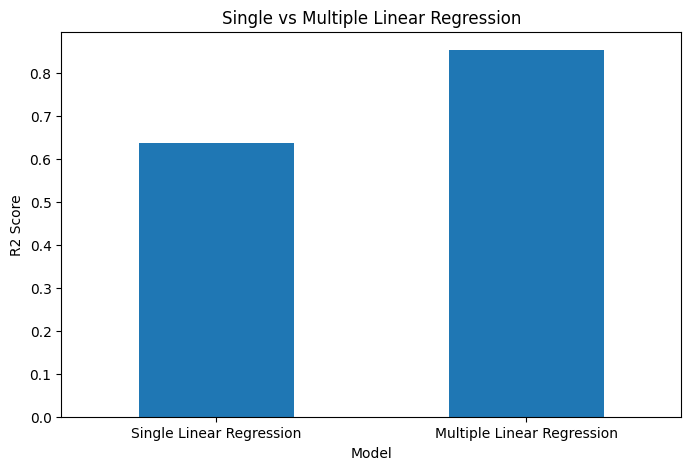

In [107]:
model_comparison.set_index('Model')[['R2 Score']].plot(
    kind='bar',
    figsize=(8, 5),
    legend=False
)

plt.title('Single vs Multiple Linear Regression')
plt.ylabel('R2 Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.show()

In [109]:
model_comparison

,Model,RMSE,MAE,R2 Score
0,Single Linear Regression,31488.553012,24571.849723,0.637404
1,Multiple Linear Regression,19969.961933,14825.016783,0.854162


In [110]:
y_train_pred = multi_model.predict(X_train_processed)

train_r2 = r2_score(y_train, y_train_pred)

print("Training R2 Score:", train_r2)

Training R2 Score: 0.872574479854271


In [111]:
test_r2 = r2_score(y_test, y_pred_multi)

print("Testing R2 Score:", test_r2)

Testing R2 Score: 0.8541615713792057


In [112]:
print("Training R2:", train_r2)
print("Testing R2:", test_r2)

difference = train_r2 - test_r2

print("R2 Difference:", difference)

Training R2: 0.872574479854271
Testing R2: 0.8541615713792057
R2 Difference: 0.01841290847506527


In [113]:
from sklearn.model_selection import cross_val_score

from sklearn.pipeline import Pipeline

cv_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

print("Cross Validation Scores:", cv_scores)

print("Average CV R2:", cv_scores.mean())

Cross Validation Scores: [0.82234348 0.84983399 0.8072981  0.83547264 0.84623908]
Average CV R2: 0.8322374594854633


In [114]:
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train, y_train)

ridge_pred = ridge_pipeline.predict(X_test)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_pred)
)

ridge_mae = mean_absolute_error(
    y_test, ridge_pred
)

ridge_r2 = r2_score(
    y_test, ridge_pred
)

print("Ridge Regression Results")
print("-------------------------")
print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2 Score:", ridge_r2)

Ridge Regression Results
-------------------------
RMSE: 20069.97105495149
MAE: 14901.28618747701
R2 Score: 0.8526972026039688


In [115]:
import joblib

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

final_model.fit(X_train, y_train)

joblib.dump(
    final_model,
    'salary_prediction_pipeline.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [116]:
loaded_model = joblib.load(
    'salary_prediction_pipeline.pkl'
)

test_prediction = loaded_model.predict(X_test)

print("First 5 salary predictions:")
print(test_prediction[:5])

First 5 salary predictions:
[ 55202.1900473  124617.08325239 167871.16618857  47260.17350056
  21660.56147066]


In [117]:
print(df_clean.columns.tolist())

print(df_clean['Gender'].unique())
print(df_clean['Education Level'].unique())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']
['Male' 'Female' 'Other']
["Bachelor's" "Master's" 'PhD' "Bachelor's Degree" "Master's Degree" nan
 'High School' 'phD']


In [118]:
new_employee = pd.DataFrame([{
    'Age': 28,
    'Gender': 'Male',
    'Education Level': "Bachelor's",
    'Job Title': 'Data Analyst',
    'Years of Experience': 5
}])

predicted_salary = loaded_model.predict(new_employee)

print("Predicted Salary:", predicted_salary[0])

Predicted Salary: 125091.26150298832


In [119]:
import joblib

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

final_model.fit(X_train, y_train)

joblib.dump(
    final_model,
    'salary_prediction_pipeline.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [120]:
loaded_model = joblib.load(
    'salary_prediction_pipeline.pkl'
)

test_prediction = loaded_model.predict(X_test)

print("First 5 predictions:")
print(test_prediction[:5])

First 5 predictions:
[ 55202.1900473  124617.08325239 167871.16618857  47260.17350056
  21660.56147066]


In [121]:
from google.colab import files

files.download('salary_prediction_pipeline.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [122]:
readme = """
 Salary Prediction Using Linear Regression

 Project Overview
This project predicts employee salaries using
Single and Multiple Linear Regression.

 Objectives
- Analyse salary datasets.
- Perform data cleaning.
- Conduct Exploratory Data Analysis.
- Implement Single Linear Regression.
- Implement Multiple Linear Regression.
- Evaluate models using RMSE, MAE and R2.
- Save the trained model.

 Dataset
Salary prediction datasets containing experience,
age, gender, education, job title and salary.

 Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

 Machine Learning Algorithms
1. Single Linear Regression
2. Multiple Linear Regression
3. Ridge Regression (optional experiment)

 Multiple Linear Regression Results
- RMSE: 19969.96
- MAE: 14825.02
- R2 Score: 0.8542

Model Saving
salary_prediction_pipeline.pkl

Conclusion
The project demonstrates how employee salary
can be predicted using Linear Regression.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [123]:
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [124]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.7 MB/s  0:00:00


In [126]:

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import inch

# Create PDF
pdf = SimpleDocTemplate(
    "Project_Report.pdf",
    pagesize=A4,
    rightMargin=45,
    leftMargin=45,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ProjectTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    fontSize=20,
    spaceAfter=15
)

content = []

# Title
content.append(Paragraph(
    "SALARY PREDICTION",
    title_style
))

content.append(Paragraph(
    "Machine Learning Project Using Linear Regression",
    ParagraphStyle(
        "Subtitle",
        parent=styles["Normal"],
        alignment=TA_CENTER,
        fontSize=12
    )
))

content.append(Spacer(1, 25))

# 1 Introduction
content.append(Paragraph("1. Introduction", styles["Heading2"]))
content.append(Paragraph(
    "This project focuses on predicting employee salaries "
    "using machine learning. Salary predictions are developed "
    "using employee information such as age, education level, "
    "job title and years of experience.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 2 Objectives
content.append(Paragraph("2. Project Objectives", styles["Heading2"]))

objectives = [
    "Understand and analyse salary datasets.",
    "Perform data cleaning and preprocessing.",
    "Conduct Exploratory Data Analysis (EDA).",
    "Implement Single Linear Regression.",
    "Implement Multiple Linear Regression.",
    "Evaluate models using RMSE, MAE and R2 Score.",
    "Save the trained machine learning pipeline."
]

for item in objectives:
    content.append(Paragraph("• " + item, styles["BodyText"]))

content.append(Spacer(1, 12))

# 3 Dataset
content.append(Paragraph("3. Dataset Description", styles["Heading2"]))
content.append(Paragraph(
    "The project uses two salary datasets. The first dataset "
    "contains YearsExperience and Salary for Single Linear "
    "Regression. The second dataset contains Age, Gender, "
    "Education Level, Job Title, Years of Experience and Salary "
    "for Multiple Linear Regression.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 4 Technologies
content.append(Paragraph("4. Technologies Used", styles["Heading2"]))

tech_data = [
    ["Technology", "Purpose"],
    ["Python", "Programming language"],
    ["Google Colab", "Development environment"],
    ["Pandas and NumPy", "Data handling"],
    ["Matplotlib and Seaborn", "Data visualization"],
    ["Scikit-learn", "Machine learning"],
    ["Joblib", "Saving the model"]
]

table = Table(tech_data, colWidths=[2*inch, 3.5*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 8),
    ("VALIGN", (0, 0), (-1, -1), "TOP")
]))
content.append(table)
content.append(Spacer(1, 12))

# 5 Methodology
content.append(Paragraph("5. Project Methodology", styles["Heading2"]))

steps = [
    "Dataset collection and understanding",
    "Data cleaning and preprocessing",
    "Exploratory Data Analysis",
    "Feature selection",
    "Train-test split",
    "Single Linear Regression training",
    "Multiple Linear Regression training",
    "Model evaluation and comparison",
    "Model saving"
]

for i, step in enumerate(steps, 1):
    content.append(Paragraph(f"{i}. {step}", styles["BodyText"]))

content.append(Spacer(1, 12))

# 6 Algorithms
content.append(Paragraph("6. Machine Learning Algorithms", styles["Heading2"]))
content.append(Paragraph(
    "<b>Single Linear Regression:</b> Predicts salary using "
    "one input feature, Years of Experience.<br/><br/>"
    "<b>Multiple Linear Regression:</b> Predicts salary using "
    "multiple input features such as age, education, job title "
    "and years of experience.<br/><br/>"
    "<b>Ridge Regression:</b> Used as an optional regularization "
    "experiment for comparison.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 7 Evaluation
content.append(Paragraph("7. Model Evaluation", styles["Heading2"]))
content.append(Paragraph(
    "The Multiple Linear Regression model was evaluated "
    "using the following actual test results:",
    styles["BodyText"]
))

metrics = [
    ["Metric", "Result"],
    ["RMSE", "19969.96"],
    ["MAE", "14825.02"],
    ["R2 Score", "0.8542"],
    ["Average 5-Fold CV R2", "0.8322"]
]

metric_table = Table(metrics, colWidths=[2.5*inch, 3*inch])
metric_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 8)
]))
content.append(metric_table)
content.append(Spacer(1, 12))

# 8 Overfitting
content.append(Paragraph("8. Overfitting Analysis", styles["Heading2"]))
content.append(Paragraph(
    "The training R2 score was 0.8726 and the testing R2 score "
    "was 0.8542. The small difference of approximately 0.0184 "
    "indicates that there is no large training-testing performance "
    "gap in this experiment.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 9 Saved Model
content.append(Paragraph("9. Saved Model", styles["Heading2"]))
content.append(Paragraph(
    "The complete preprocessing and Multiple Linear Regression "
    "pipeline was saved using Joblib as "
    "<b>salary_prediction_pipeline.pkl</b>.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 10 Conclusion
content.append(Paragraph("10. Conclusion", styles["Heading2"]))
content.append(Paragraph(
    "This project demonstrates how Linear Regression can be "
    "used for salary prediction. It includes data preparation, "
    "visualization, single and multiple regression, model "
    "evaluation and model saving. The Multiple Linear Regression "
    "model achieved an R2 score of approximately 0.8542 on "
    "the test dataset.",
    styles["BodyText"]
))
content.append(Spacer(1, 12))

# 11 References
content.append(Paragraph("11. References", styles["Heading2"]))
content.append(Paragraph(
    "1. Salary dataset used for Single Linear Regression.<br/>"
    "2. Salary dataset used for Multiple Linear Regression.<br/>"
    "3. Scikit-learn Documentation: https://scikit-learn.org/<br/>"
    "4. Pandas Documentation: https://pandas.pydata.org/",
    styles["BodyText"]
))

# Generate PDF
pdf.build(content)

print("Project_Report.pdf created successfully!")


Project_Report.pdf created successfully!


In [127]:
from google.colab import files

files.download("Project_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [128]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
reportlab
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [129]:
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [130]:
files.download("Salary_Multiple_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [131]:
files.download("Salary_Multiple_Regression.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [132]:
files.download("Salary_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [133]:
files.download("salary_prediction_pipeline.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [134]:
files.download("README.md")
files.download("Project_Report.pdf")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>